<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/14_Implement_House_price_Prediction_using_appropriate_machine_learning_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction using Machine Learning
This notebook demonstrates a complete workflow for predicting house prices using regression algorithms. We will:
1. Generate a synthetic dataset representing houses.
2. Explore and preprocess the data.
3. Train Linear Regression and Random Forest Regressor models.
4. Evaluate and compare the models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set random seed for reproducibility
np.random.seed(42)

### 1. Data Generation
We create a synthetic dataset containing features such as:
* `Size_sqft`: Square footage of the house
* `Bedrooms`: Number of bedrooms
* `Age`: Age of the house in years
* `Price`: Price of the house (Target)

In [2]:
# Generate synthetic data
n_samples = 500
size = np.random.normal(2000, 500, n_samples).astype(int)
bedrooms = np.random.randint(1, 6, n_samples)
age = np.random.randint(0, 50, n_samples)

# Calculate house price with some added noise
price = (size * 150) + (bedrooms * 15000) - (age * 1200) + np.random.normal(50000, 15000, n_samples)

# Create a DataFrame
df = pd.DataFrame({
    'Size_sqft': size,
    'Bedrooms': bedrooms,
    'Age': age,
    'Price': price
})

display(df.head())

,Size_sqft,Bedrooms,Age,Price
0,2248,2,9,386979.777864
1,1930,2,29,352112.401811
2,2323,3,24,407634.481980
3,2761,3,38,468747.558226
4,1882,5,19,383796.191317


### 2. Data Splitting and Feature Scaling

In [3]:
# Split features and target
X = df.drop('Price', axis=1)
y = df['Price']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features for better model convergence/performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (400, 3)
Testing set shape: (100, 3)


### 3. Model Training & Evaluation

In [4]:
# Initialize models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train models
lr_model.fit(X_train_scaled, y_train)
rf_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)

# Define a helper function to print metrics
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} Performance ---")
    print(f"R2 Score: {r2:.4f}")
    print(f"MAE: ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}\n")

evaluate_model("Linear Regression", y_test, y_pred_lr)
evaluate_model("Random Forest Regressor", y_test, y_pred_rf)

--- Linear Regression Performance ---
R2 Score: 0.9712
MAE: $10,717.41
RMSE: $13,429.02

--- Random Forest Regressor Performance ---
R2 Score: 0.9349
MAE: $14,648.07
RMSE: $20,189.51



### 4. Visualizing Predicted vs Actual Prices

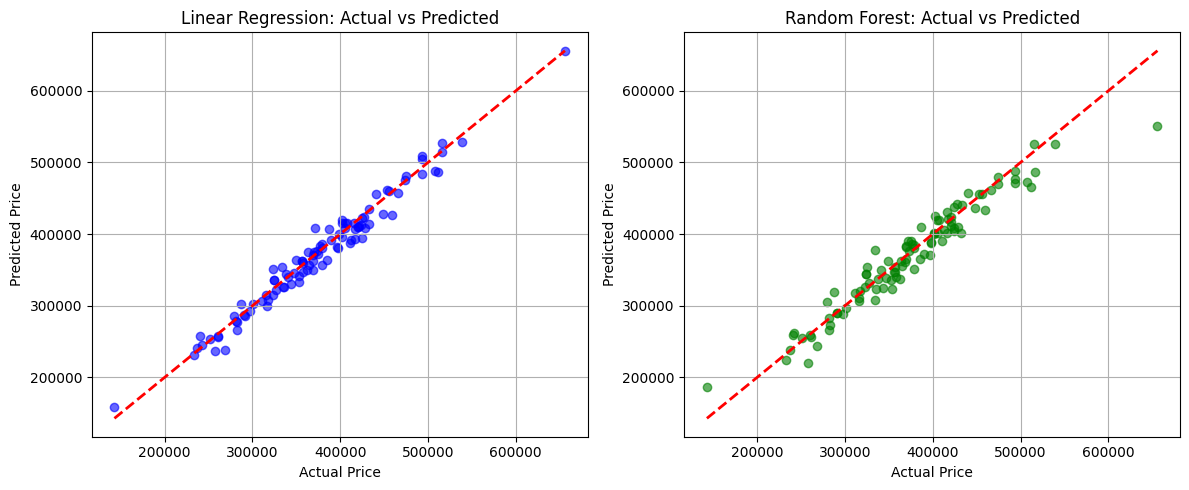

In [5]:
plt.figure(figsize=(12, 5))

# Plot Linear Regression results
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lr, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Linear Regression: Actual vs Predicted')
plt.grid(True)

# Plot Random Forest results
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_rf, alpha=0.6, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Random Forest: Actual vs Predicted')
plt.grid(True)

plt.tight_layout()
plt.show()